# **Flight Price Prediction**

### **Problem Statement**

 The objective of this project is to predict flight ticket prices based on various factors such as airline, source, destination,
 journey date, duration, number of stops, and additional flight information.

Task 1:-Prepare a complete data analysis report on the given data.

Task 2:-Create a predictive model which will help the customers to predict future flight prices and plan their journey accordingly.

### Attribute Information :

1.	Airline: So this column will have all the types of airlines like Indigo, Jet Airways, Air India, and many more.
2.	Date_of_Journey: This column will let us know about the date on which the passenger’s journey will start.
3.	Source: This column holds the name of the place from where the passenger’s journey will start.
4.	Destination: This column holds the name of the place to where passengers wanted to travel.
5.	Route: Here we can know about what the route is through which passengers have opted to travel from his/her source to their destination.
6.	Arrival_Time: Arrival time is when the passenger will reach his/her destination.
7.	Duration: Duration is the whole period that a flight will take to complete its journey from source to destination.
8.	Total_Stops: This will let us know in how many places flights will stop there for the flight in the whole journey.
9.	Additional_Info: In this column, we will get information about food, kind of food, and other amenities.
10.	Price: Price of the flight for a complete journey including all the expenses before onboarding.


In [ ]:
#importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
#Load dataset
df=pd.read_excel('Flight_Fare.xlsx')

## **Basic Checks**

In [ ]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [ ]:
df.shape

(10683, 11)

In [ ]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='object')

## **Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) is performed to understand the structure of the dataset, identify missing values, detect duplicate records, and analyze the distribution of features. It helps uncover patterns and relationships in the data before preprocessing and model building.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [ ]:
df.describe()


,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [ ]:
df.isnull().sum()


,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


## **Missing Values Heatmap**

A heatmap is used to visualize the distribution of missing values in the dataset. It helps identify which columns contain missing data and whether further preprocessing is required before model building.

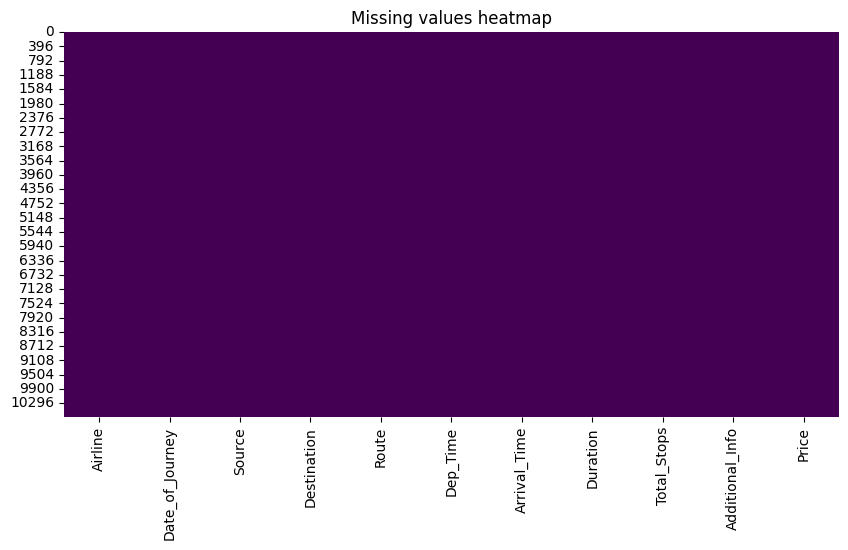

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),cbar=False,cmap='viridis')
plt.title('Missing values heatmap')
plt.show()

In [ ]:
df.duplicated().sum()

np.int64(220)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,0
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,0
Additional_Info,0


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(10462, 11)

## **Feature Engineering: Date of Journey**

The `Date_of_Journey` column is converted into a datetime format to extract useful features such as **Journey Day**, **Journey Month**, and **Journey Year**. These features help the model capture seasonal and date-related patterns that may influence flight ticket prices.


In [ ]:
df["Date_of_Journey"]= pd.to_datetime(df["Date_of_Journey"])

In [ ]:
df["Journey_Day"]=df["Date_of_Journey"].dt.day
df["Journey_Month"]=df["Date_of_Journey"].dt.month
df["Journey_Year"]=df["Date_of_Journey"].dt.year

In [ ]:
df[["Date_of_Journey","Journey_Day","Journey_Month","Journey_Year"]].head()

,Date_of_Journey,Journey_Day,Journey_Month,Journey_Year
0,2019-03-24,24,3,2019
1,2019-05-01,1,5,2019
2,2019-06-09,9,6,2019
3,2019-05-12,12,5,2019
4,2019-03-01,1,3,2019


In [ ]:
df.drop("Date_of_Journey", axis=1, inplace=True)

In [ ]:
df["Dep_Time"].head()

,Dep_Time
0,22:20
1,05:50
2,09:25
3,18:05
4,16:50


In [ ]:
df["Dep_Hour"]=pd.to_datetime(df["Dep_Time"]).dt.hour
df["Dep_Min"]=pd.to_datetime(df["Dep_Time"]).dt.minute

In [ ]:
df.drop("Dep_Time",axis=1,inplace=True)

In [ ]:
df["Arrival_Time"].head()

,Arrival_Time
0,01:10 22 Mar
1,13:15
2,04:25 10 Jun
3,23:30
4,21:35


In [ ]:
df["Arrival_Hour"]=pd.to_datetime(df["Arrival_Time"]).dt.hour
df["Arrival_Min"]=pd.to_datetime(df["Arrival_Time"]).dt.minute

In [ ]:
df.drop("Arrival_Time",axis=1,inplace=True)

In [ ]:
df["Duration"].head()

,Duration
0,2h 50m
1,7h 25m
2,19h
3,5h 25m
4,4h 45m


### Duration Conversion

The `Duration` column is converted from text format (e.g., `2h 50m`) into total minutes. Converting it into a numerical feature makes it suitable for machine learning algorithms and improves model performance.


In [ ]:
def convert_duration(duration):
  hours=0
  minutes=0
  if 'h' in duration:
    hours=duration.split('h')[0]
  if 'm' in duration:
    if 'h' in duration:
      minutes=duration.split('h')[1].replace('m','').strip()
    else:
      minutes=duration.replace('m','').strip()
  return int(hours)*60+int(minutes)

In [ ]:
df["Duration_minutes"]=df["Duration"].apply(convert_duration)

In [ ]:
df[["Duration","Duration_minutes"]].head()

,Duration,Duration_minutes
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285


In [ ]:
df.drop("Duration",axis=1,inplace=True)

In [ ]:
df.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,24,3,2019,22,20,1,10,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,5,2019,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,9,6,2019,9,25,4,25,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,12,5,2019,18,5,23,30,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,1,3,2019,16,50,21,35,285


In [ ]:
df["Total_Stops"].value_counts()

,count
Total_Stops,
1 stop,5625
non-stop,3475
2 stops,1318
3 stops,43
4 stops,1


In [ ]:
df["Total_Stops"]=df["Total_Stops"].map({'non-stop':0,'1 stop':1,'2 stops':2,'3 stops':3,'4 stops':4})

In [ ]:
df["Total_Stops"].head()

,Total_Stops
0,0
1,2
2,2
3,1
4,1


### Unique Value Analysis

The number of unique values in each categorical feature is examined to understand the cardinality of the data. This helps in deciding the appropriate encoding technique and identifying features with a large number of categories.


In [ ]:
for col in ["Airline","Source","Destination","Route","Additional_Info"]:
  print(f"{col} has {df[col].nunique()} unique values")

Airline has 12 unique values
Source has 5 unique values
Destination has 6 unique values
Route has 128 unique values
Additional_Info has 10 unique values


In [ ]:
df["Airline"].value_counts()

,count
Airline,
Jet Airways,3700
IndiGo,2043
Air India,1694
Multiple carriers,1196
SpiceJet,815
Vistara,478
Air Asia,319
GoAir,194
Multiple carriers Premium economy,13


In [ ]:
airline=pd.get_dummies(df["Airline"],drop_first=True)
airline.head()

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,Vistara Premium economy
0,False,False,True,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,True,False,False,False,False,False,False,False,False


In [ ]:
source=pd.get_dummies(df["Source"],drop_first=True)
source.head()

,Chennai,Delhi,Kolkata,Mumbai
0,False,False,False,False
1,False,False,True,False
2,False,True,False,False
3,False,False,True,False
4,False,False,False,False


In [ ]:
destination=pd.get_dummies(df["Destination"],drop_first=True)
destination.head()

,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
0,False,False,False,False,True
1,False,False,False,False,False
2,True,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,True


In [ ]:
df["Additional_Info"].value_counts()

,count
Additional_Info,
No info,8182
In-flight meal not included,1926
No check-in baggage included,318
1 Long layover,19
Change airports,7
Business class,4
No Info,3
1 Short layover,1
Red-eye flight,1


In [ ]:
df.drop("Additional_Info",axis=1,inplace=True)

In [ ]:
df["Route"].nunique()

128

In [ ]:
df["Route"].value_counts().head(10)

,count
Route,
DEL → BOM → COK,2376
BLR → DEL,1536
CCU → BOM → BLR,979
CCU → BLR,724
BOM → HYD,621
CCU → DEL → BLR,565
BLR → BOM → DEL,402
MAA → CCU,381
DEL → HYD → COK,326


In [ ]:
df.drop("Route",axis=1,inplace=True)

In [ ]:
df=pd.concat([df,airline,source,destination],axis=1)

In [ ]:
df.drop(["Airline","Source","Destination"],axis=1,inplace=True)

In [ ]:
df.head()

,Total_Stops,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_minutes,...,Vistara Premium economy,Chennai,Delhi,Kolkata,Mumbai,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
0,0,3897,24,3,2019,22,20,1,10,170,...,False,False,False,False,False,False,False,False,False,True
1,2,7662,1,5,2019,5,50,13,15,445,...,False,False,False,True,False,False,False,False,False,False
2,2,13882,9,6,2019,9,25,4,25,1140,...,False,False,True,False,False,True,False,False,False,False
3,1,6218,12,5,2019,18,5,23,30,325,...,False,False,False,True,False,False,False,False,False,False
4,1,13302,1,3,2019,16,50,21,35,285,...,False,False,False,False,False,False,False,False,False,True


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10462 entries, 0 to 10682
Data columns (total 30 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Total_Stops                        10462 non-null  int64
 1   Price                              10462 non-null  int64
 2   Journey_Day                        10462 non-null  int32
 3   Journey_Month                      10462 non-null  int32
 4   Journey_Year                       10462 non-null  int32
 5   Dep_Hour                           10462 non-null  int32
 6   Dep_Min                            10462 non-null  int32
 7   Arrival_Hour                       10462 non-null  int32
 8   Arrival_Min                        10462 non-null  int32
 9   Duration_minutes                   10462 non-null  int64
 10  Air India                          10462 non-null  bool 
 11  GoAir                              10462 non-null  bool 
 12  IndiGo                 

In [ ]:
X=df.drop("Price",axis=1)
y=df["Price"]

In [ ]:
print(X.shape)
print(y.shape)


(10462, 29)
(10462,)


### Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. The training set is used to train the machine learning models, while the testing set is used to evaluate their performance on unseen data.


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8369, 29)
(2093, 29)
(8369,)
(2093,)


### Model Evaluation Function

A reusable function is created to train and evaluate different machine learning models. The function calculates key performance metrics such as **MAE**, **MSE**, **RMSE**, and **R² Score**, making it easier to compare the performance of multiple regression models.


In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
def evaluate_model(model,X_test,X_train,y_test,y_train):
  model.fit(X_train,y_train)
  y_pred=model.predict(X_test)
  mae=mean_absolute_error(y_test,y_pred)
  mse=mean_squared_error(y_test,y_pred)
  rmse=mse**0.5
  r2=r2_score(y_test,y_pred)

  print(f"model:{model.__class__.__name__}")
  print("MAE",round(mae,2))
  print("MSE",round(mse,2))
  print("RMSE",round(rmse,2))
  print("R2",round(r2,2))

  return{
      "model":model.__class__.__name__,
      "MAE":mae,
      "MSE":mse,
      "RMSE":rmse,
      "R2":r2
  }



## Model Creation

In this section, multiple machine learning regression models are created and trained using the prepared training dataset. Each model is evaluated using MAE, MSE, RMSE, and R² Score to compare their performance and identify the most suitable model for flight price prediction.


In [ ]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr_result=evaluate_model(lr,X_test,X_train,y_test,y_train)


model:LinearRegression
MAE 1998.64
MSE 8677715.46
RMSE 2945.8
R2 0.58


In [ ]:
y_pred=lr.predict(X_test)

In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt=DecisionTreeRegressor(random_state=42)
dt_result=evaluate_model(dt,X_test,X_train,y_test,y_train)

model:DecisionTreeRegressor
MAE 1379.8
MSE 5847424.31
RMSE 2418.14
R2 0.72


In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=100,random_state=42)
rf_result=evaluate_model(rf,X_test,X_train,y_test,y_train)



model:RandomForestRegressor
MAE 1169.92
MSE 3856887.26
RMSE 1963.9
R2 0.82


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
et=ExtraTreesRegressor(n_estimators=100,random_state=42)
et_result=evaluate_model(et,X_test,X_train,y_test,y_train)

model:ExtraTreesRegressor
MAE 1224.85
MSE 4606351.49
RMSE 2146.24
R2 0.78


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
gb=GradientBoostingRegressor(random_state=42)
gb_result=evaluate_model(gb,X_test,X_train,y_test,y_train)

model:GradientBoostingRegressor
MAE 1536.72
MSE 5143364.07
RMSE 2267.9
R2 0.75


### Model Comparison

The performance of all trained regression models is compared using MAE, MSE, RMSE, and R² Score. The models are ranked based on their R² Score to identify the best-performing model for flight price prediction.


In [ ]:
results=pd.DataFrame([lr_result,dt_result,rf_result,et_result,gb_result])
results.sort_values(by="R2", ascending=False)

,model,MAE,MSE,RMSE,R2
2,RandomForestRegressor,1169.923170,3.856887e+06,1963.895940,0.815020
3,ExtraTreesRegressor,1224.854468,4.606351e+06,2146.241246,0.779075
4,GradientBoostingRegressor,1536.724775,5.143364e+06,2267.898602,0.753319
1,DecisionTreeRegressor,1379.801919,5.847424e+06,2418.144807,0.719552
0,LinearRegression,1998.639306,8.677715e+06,2945.796236,0.583808


In [1]:
#Imporatant Feature
importance=pd.Series(rf.feature_importances_,index=X.columns)
importance=importance.sort_values(ascending=False)
importance.head(10)

NameError: name 'pd' is not defined

### Feature Importance

Feature importance is analyzed to identify the variables that have the greatest influence on flight price prediction. The top 10 most important features are visualized using a bar chart to better understand their impact on the model.


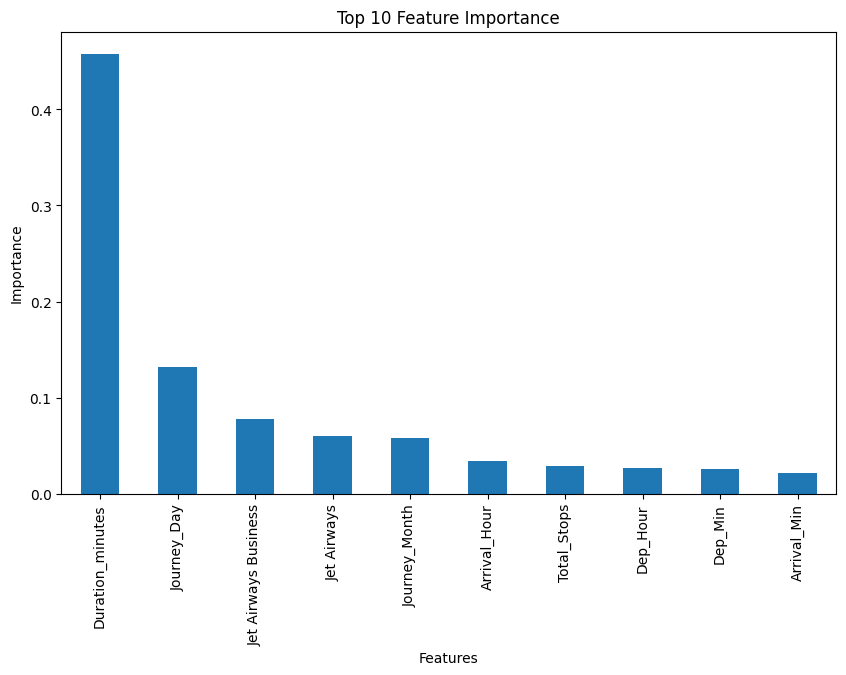

In [ ]:
plt.figure(figsize=(10,6))
importance.head(10).plot(kind="bar")
plt.title("Top 10 Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()


### Actual vs Predicted Values

A scatter plot is created to compare the actual flight prices with the prices predicted by the Random Forest model. This visualization helps evaluate how closely the model's predictions match the actual values.


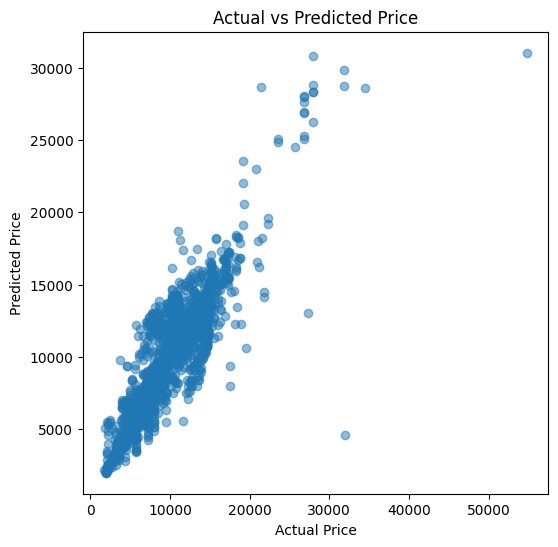

In [ ]:
y_pred=rf.predict(X_test)
plt.figure(figsize=(6,6))
plt.scatter(y_test,y_pred, alpha=0.5)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Flight Price")
plt.show()

# Model Comparison Report

Multiple regression models were trained and evaluated to predict flight ticket prices. The performance of each model was measured using **Mean Absolute Error (MAE)**, **Mean Squared Error (MSE)**, **Root Mean Squared Error (RMSE)**, and **R² Score**.

| Model                       |         MAE |        RMSE | R² Score |
| --------------------------- | ----------: | ----------: | -------: |
| Linear Regression           |     1998.64 |     2945.80 |     0.58 |
| Decision Tree Regressor     |     1379.80 |     2418.14 |     0.72 |
| Random Forest Regressor     | **1169.92** | **1963.90** | **0.82** |
| Extra Trees Regressor       |     1224.85 |     2146.24 |     0.78 |
| Gradient Boosting Regressor |     1536.72 |     2267.90 |     0.75 |

Among all the evaluated models, the **Random Forest Regressor** achieved the best overall performance with the **highest R² Score (0.82)** and the **lowest MAE and RMSE**, indicating better prediction accuracy and lower error compared to the other models.

Although the **Extra Trees Regressor** also produced good results, its performance was slightly lower than that of the Random Forest model. The **Decision Tree Regressor** performed reasonably well but is more prone to overfitting because it relies on a single decision tree. The **Gradient Boosting Regressor** achieved moderate performance, while **Linear Regression** produced the lowest accuracy due to its inability to capture the complex, non-linear relationships present in the dataset.

### Best Model

Based on the evaluation metrics, the **Random Forest Regressor** is recommended for production. It provides the most accurate and reliable predictions for flight ticket prices and demonstrates better generalization compared to the other regression models evaluated in this project.


# Report on Challenges Faced

During the development of the Flight Price Prediction model, several challenges were encountered while preprocessing the data and building the machine learning models. The following techniques were used to address these challenges:
 1. Handling Missing Values - route and total_stops
2. Removing Duplicate Records - 220 duplicate values identified
3. Feature Engineering - date_of_journey,dep_time,arrival_time,duration are not suitable
4. Encoding Categorical Variables - dataset containing multiple categorical values
5. Feature Selection
6. Model Selection




# Conclusion

This project successfully developed a machine learning model to predict flight ticket prices using historical flight data. The dataset was preprocessed by handling missing values, removing duplicate records, performing feature engineering, and encoding categorical variables.

Multiple regression models were trained and evaluated using MAE, MSE, RMSE, and R² Score. Among all the models, the **Random Forest Regressor** achieved the best performance with an **R² Score of 0.82**, making it the most suitable model for predicting flight ticket prices.

Feature importance analysis showed that **Duration_minutes**, **Journey_Day**, **Airline**, and **Journey_Month** were the most influential factors affecting flight prices. Overall, the developed model can assist customers in estimating future flight prices and planning their journeys more effectively.
